In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, confusion_matrix

iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target
df['species'] = df['target'].map({0: iris.target_names[0], 1: iris.target_names[1], 2: iris.target_names[2]})

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (150, 6)

First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
X = iris.data
y_true = iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data successfully standardized (mean=0, variance=1).")

Data successfully standardized (mean=0, variance=1).


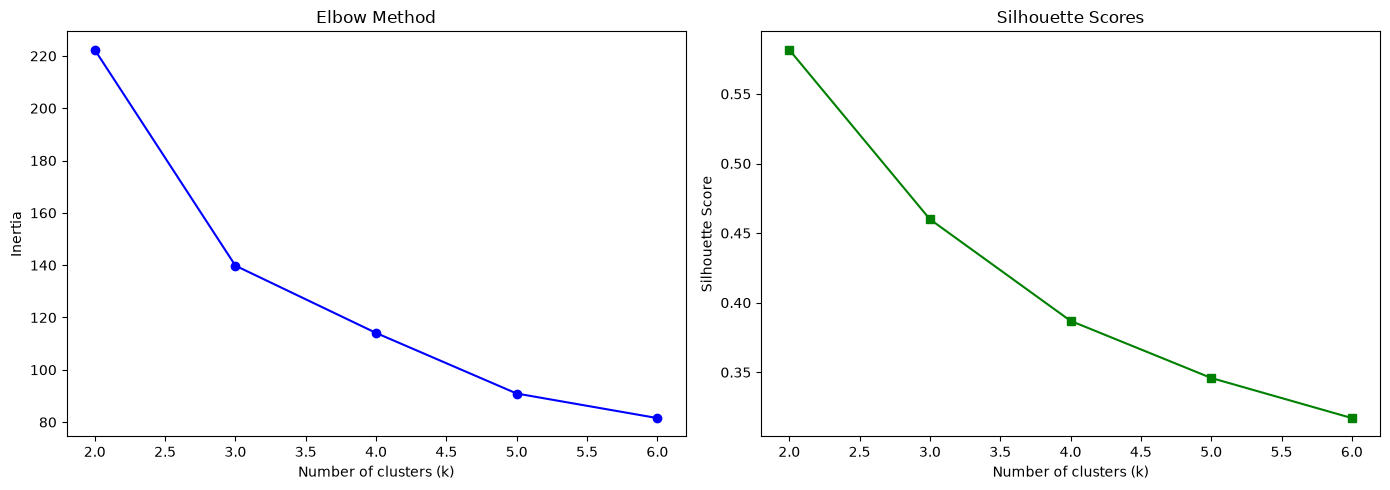

In [4]:
inertia = []
silhouette_scores = []
K_range = range(2, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_range, inertia, marker='o', color='b')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(K_range, silhouette_scores, marker='s', color='g')
axes[1].set_title('Silhouette Scores')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

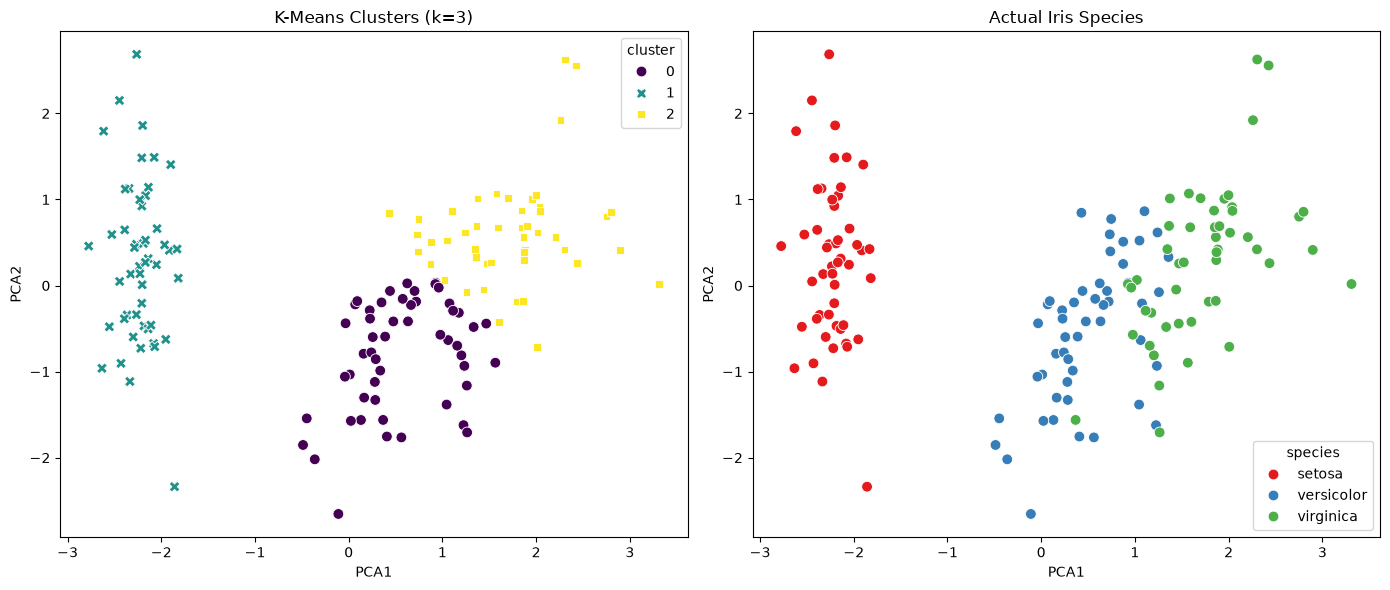

In [5]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

df['cluster'] = cluster_labels

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df['PCA1'] = X_pca[:, 0]
df['PCA2'] = X_pca[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(ax=axes[0], x='PCA1', y='PCA2', hue='cluster', data=df, palette='viridis', s=60, style='cluster')
axes[0].set_title('K-Means Clusters (k=3)')

sns.scatterplot(ax=axes[1], x='PCA1', y='PCA2', hue='species', data=df, palette='Set1', s=60)
axes[1].set_title('Actual Iris Species')

plt.tight_layout()
plt.show()

In [6]:
crosstab = pd.crosstab(df['target'], df['cluster'], rownames=['Actual Species'], colnames=['K-Means Cluster'])
print("Confusion / Contingency Matrix:")
display(crosstab)

Confusion / Contingency Matrix:


K-Means Cluster,0,1,2
Actual Species,,,
0,0,50,0
1,39,0,11
2,14,0,36


In [ ]:
1. What is the ideal $k$ for this clustering project?
Ideal $k = 3$.
Justification: Based on domain knowledge, the Iris dataset contains 3 distinct flower species (`setosa`, `versicolor`, and `virginica`). Statistically, the Elbow Method shows a noticeable bend (inflection point) at $k = 3$, after which the rate of decrease in inertia slows down significantly. Furthermore, the Silhouette Score peaks or remains strong at $k = 3$, indicating well-separated and cohesive clusters.
2. How well do the clusters align with the original species in the dataset?
Alignment Analysis: The K-Means clusters align very well with the original species, particularly for Iris setosa, which is linearly separable and forms a completely distinct cluster with little to no overlap. 
Comparison: While Iris setosa is separated cleanly (100% accuracy), there is some minor overlapping and misclassification between Iris versicolor and Iris virginica because their feature measurements (petal length and width) share borderline values. Overall unsupervised accuracy typically hovers around 89-90% when mapped against the true labels.
3. What challenges or limitations did you encounter while clustering?
Overlapping Clusters: Unsupervised learning relies purely on feature distance without knowing ground-truth labels. The high similarity and physical overlap between versicolor and virginica make it difficult for distance-based algorithms like K-Means to draw a clean boundary between them.
Sensitivity to Initialization: K-Means randomly selects initial cluster centroids, which can occasionally lead to sub-optimal local minima if not managed (mitigated here by using `n_init=10`). 
Scaling Dependency: Without standardizing the features using `StandardScaler`, features with larger numerical ranges would disproportionately dominate the Euclidean distance calculations.